
# Notebook 16: Complete Preprocessing Workflow

## Objective
Build a complete end-to-end data preprocessing workflow using
the selected Titanic dataset.

## Learning Outcomes
- Load and inspect the dataset.
- Identify data types and missing values.
- Detect and handle duplicates.
- Validate data quality.
- Detect and investigate outliers.
- Encode categorical variables.
- Scale numerical variables.
- Evaluate class imbalance.
- Perform feature selection.
- Split data correctly.
- Build a Scikit-learn preprocessing pipeline.
- Validate and export the final ML-ready dataset.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data_url = (
    "https://raw.githubusercontent.com/"
    "datasciencedojo/datasets/master/titanic.csv"
)

df = pd.read_csv(data_url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Statistical summary:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN



Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset dimensions:
Rows: 891
Columns: 12


In [4]:
print("Data types:")
display(df.dtypes.to_frame("Data_Type"))

numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Data types:


,Data_Type
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64



Numerical columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical columns:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [5]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


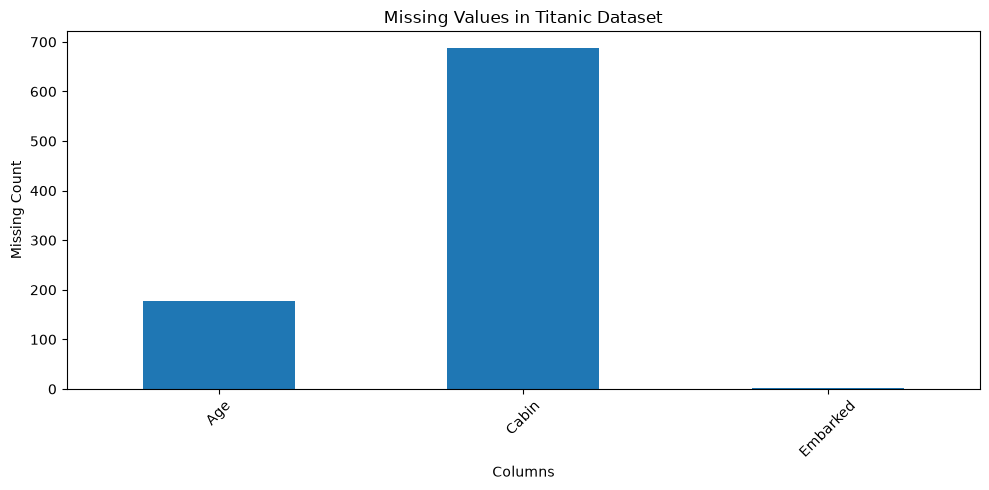

In [6]:
missing_counts = df.isnull().sum()

missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(10, 5))
missing_counts.plot(kind="bar")

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates after cleaning:", df.duplicated().sum())

print("Dataset shape after duplicate removal:", df.shape)

Duplicates before cleaning: 0
Duplicates after cleaning: 0
Dataset shape after duplicate removal: (891, 12)


In [8]:
print("Checking target variable:")

print(df["Survived"].value_counts(dropna=False))

print("\nChecking invalid values:")

print("Negative Age values:", (df["Age"] < 0).sum())
print("Negative Fare values:", (df["Fare"] < 0).sum())
print("Negative SibSp values:", (df["SibSp"] < 0).sum())
print("Negative Parch values:", (df["Parch"] < 0).sum())

print("\nTarget missing values:", df["Survived"].isnull().sum())

Checking target variable:
Survived
0    549
1    342
Name: count, dtype: int64

Checking invalid values:
Negative Age values: 0
Negative Fare values: 0
Negative SibSp values: 0
Negative Parch values: 0

Target missing values: 0



## Data Validation

Validation checks whether the dataset follows expected rules.

Rules used:
- Age cannot be negative.
- Fare cannot be negative.
- SibSp and Parch cannot be negative.
- Survived must contain only 0 or 1.
- Passenger records must contain valid target values.

Invalid observations should be investigated before removal
or correction.


In [9]:
outlier_columns = ["Age", "Fare", "SibSp", "Parch"]

for column in outlier_columns:

    values = df[column].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    print(f"\n{column}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Potential outliers:", outliers)


Age
Lower bound: -6.6875
Upper bound: 64.8125
Potential outliers: 11

Fare
Lower bound: -26.724
Upper bound: 65.6344
Potential outliers: 116

SibSp
Lower bound: -1.5
Upper bound: 2.5
Potential outliers: 46

Parch
Lower bound: 0.0
Upper bound: 0.0
Potential outliers: 213


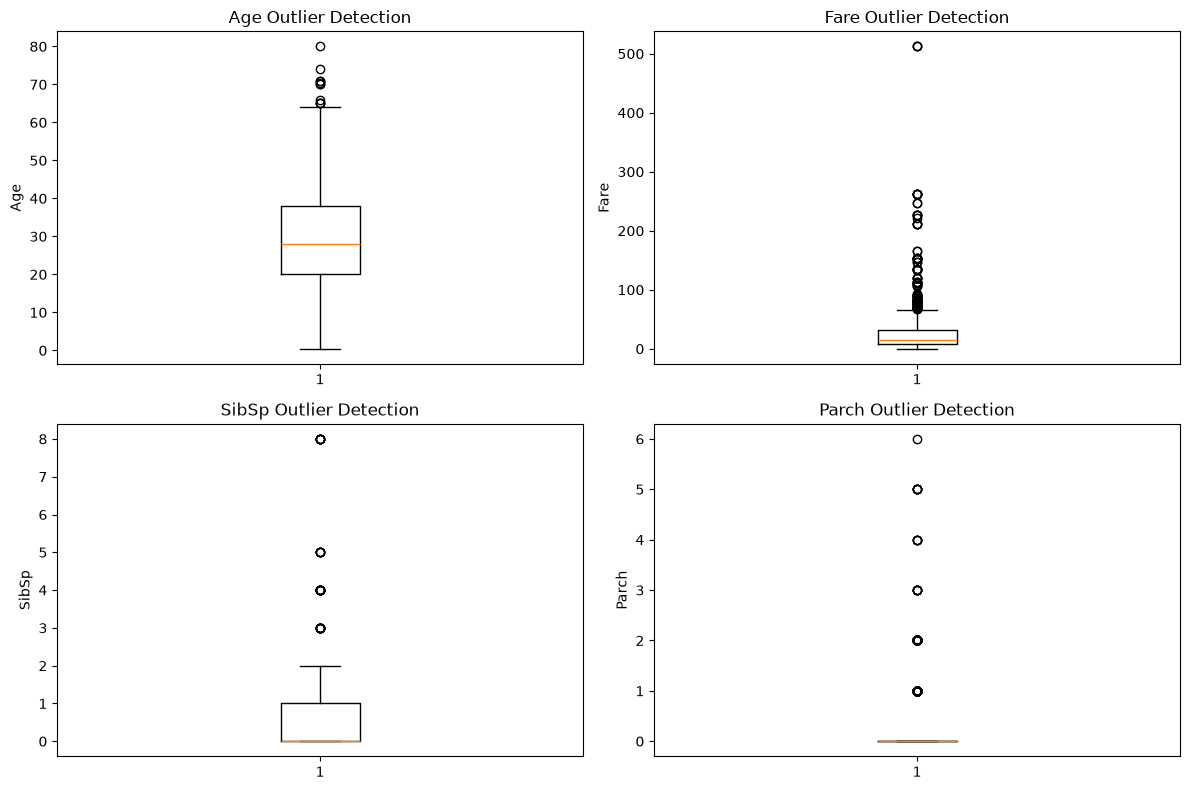

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, outlier_columns):
    ax.boxplot(df[column].dropna())
    ax.set_title(f"{column} Outlier Detection")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()


## Outlier Treatment

Potential outliers were identified using the IQR method.

However, not every extreme observation is an error.

Examples:
- High passenger fares may represent premium cabins.
- Large family sizes may represent genuine passenger groups.
- Unusual ages should be checked for validity.

Decision:
- Retain valid extreme observations.
- Investigate impossible values.
- Avoid automatic deletion.
- Use RobustScaler to reduce the influence of extreme
  numerical values during scaling.

Outlier treatment should be based on domain knowledge.


In [11]:
df_model = df.copy()

# Remove records without a target value.
df_model = df_model.dropna(subset=["Survived"])

# Feature engineering.
df_model["FamilySize"] = (
    df_model["SibSp"] +
    df_model["Parch"] + 1
)

# Remove unsuitable columns.
columns_to_drop = [
    "PassengerId",
    "Name",
    "Ticket",
    "Cabin"
]

df_model = df_model.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Prepared dataset shape:", df_model.shape)

display(df_model.head())

Prepared dataset shape: (891, 9)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,0,3,male,22.0,1,0,7.2500,S,2
1,1,1,female,38.0,1,0,71.2833,C,2
2,1,3,female,26.0,0,0,7.9250,S,1
3,1,1,female,35.0,1,0,53.1000,S,2
4,0,3,male,35.0,0,0,8.0500,S,1


In [12]:
target = "Survived"

numerical_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]

X = df_model[numerical_features + categorical_features]
y = df_model[target].astype(int)

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTarget:")
print(target)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Numerical features:
['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']

Categorical features:
['Pclass', 'Sex', 'Embarked']

Target:
Survived

Feature shape: (891, 8)
Target shape: (891,)


In [13]:
class_counts = y.value_counts().sort_index()

print("Target class counts:")
display(class_counts.to_frame("Count"))

print("\nTarget class percentages:")
display(
    (y.value_counts(normalize=True) * 100)
    .sort_index()
    .to_frame("Percentage")
    .round(2)
)

Target class counts:


,Count
Survived,
0,549
1,342



Target class percentages:


,Percentage
Survived,
0,61.62
1,38.38


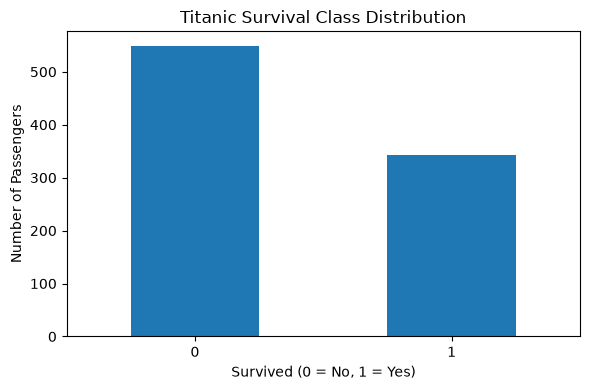

In [14]:
class_counts.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Titanic Survival Class Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Handling Class Imbalance

The Titanic dataset contains two target classes:
- 0: Did not survive.
- 1: Survived.

The class distribution is unequal, but the imbalance is not
extreme.

Decision:
- Preserve the original class distribution.
- Do not automatically apply SMOTE or undersampling.
- Use stratified sampling when splitting the data.
- Evaluate precision, recall, F1-score, and balanced accuracy.

Resampling should only be introduced when justified by
training-data evaluation.


In [15]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
display(y_train.value_counts().sort_index())

print("\nValidation class distribution:")
display(y_val.value_counts().sort_index())

print("\nTesting class distribution:")
display(y_test.value_counts().sort_index())

Training shape: (534, 8)
Validation shape: (178, 8)
Testing shape: (179, 8)

Training class distribution:


Survived
0    329
1    205
Name: count, dtype: int64


Validation class distribution:


Survived
0    110
1     68
Name: count, dtype: int64


Testing class distribution:


Survived
0    110
1     69
Name: count, dtype: int64

In [16]:
from sklearn.preprocessing import RobustScaler

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

print("Numerical pipeline created successfully!")

Numerical pipeline created successfully!


In [17]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical pipeline created successfully!")

Categorical pipeline created successfully!


In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [19]:
feature_selector = SelectKBest(
    score_func=f_classif,
    k=10
)

print("Feature selector created successfully!")

Feature selector created successfully!


In [20]:
complete_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("feature_selection", feature_selector),
    ("model", LogisticRegression(max_iter=1000))
])

print("Complete preprocessing pipeline created!")

Complete preprocessing pipeline created!


In [21]:
complete_pipeline.fit(X_train, y_train)

print("Pipeline training completed successfully!")

Pipeline training completed successfully!


In [22]:
val_predictions = complete_pipeline.predict(X_val)

print("Validation Accuracy:",
      round(accuracy_score(y_val, val_predictions), 4))

print("Validation Precision:",
      round(precision_score(y_val, val_predictions), 4))

print("Validation Recall:",
      round(recall_score(y_val, val_predictions), 4))

print("Validation F1 Score:",
      round(f1_score(y_val, val_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_val, val_predictions))

Validation Accuracy: 0.7921
Validation Precision: 0.746
Validation Recall: 0.6912
Validation F1 Score: 0.7176

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.84       110
           1       0.75      0.69      0.72        68

    accuracy                           0.79       178
   macro avg       0.78      0.77      0.78       178
weighted avg       0.79      0.79      0.79       178



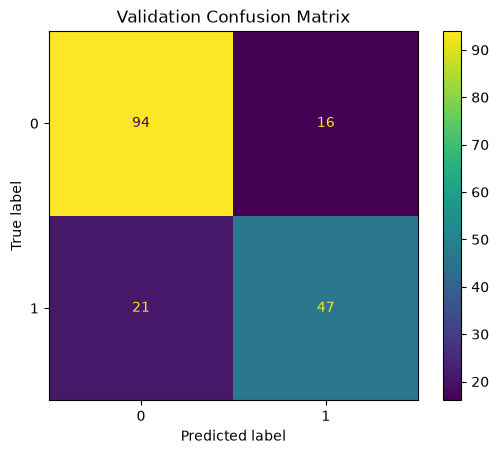

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions
)

plt.title("Validation Confusion Matrix")
plt.show()

In [24]:
fitted_preprocessor = complete_pipeline.named_steps["preprocessor"]
fitted_selector = complete_pipeline.named_steps["feature_selection"]

# Transform each dataset using the fitted preprocessing steps.
X_train_transformed = fitted_preprocessor.transform(X_train)
X_val_transformed = fitted_preprocessor.transform(X_val)
X_test_transformed = fitted_preprocessor.transform(X_test)

# Apply the fitted feature selector.
X_train_selected = fitted_selector.transform(X_train_transformed)
X_val_selected = fitted_selector.transform(X_val_transformed)
X_test_selected = fitted_selector.transform(X_test_transformed)

# Get selected feature names.
all_feature_names = fitted_preprocessor.get_feature_names_out()
selected_feature_names = all_feature_names[
    fitted_selector.get_support()
]

print("Selected features:")
print(selected_feature_names.tolist())

print("\nTraining processed shape:", X_train_selected.shape)
print("Validation processed shape:", X_val_selected.shape)
print("Testing processed shape:", X_test_selected.shape)

Selected features:
['numerical__Age', 'numerical__Parch', 'numerical__Fare', 'numerical__FamilySize', 'categorical__Pclass_1', 'categorical__Pclass_3', 'categorical__Sex_female', 'categorical__Sex_male', 'categorical__Embarked_C', 'categorical__Embarked_S']

Training processed shape: (534, 10)
Validation processed shape: (178, 10)
Testing processed shape: (179, 10)


In [25]:
def to_dense_array(data):
    if hasattr(data, "toarray"):
        return data.toarray()
    return np.asarray(data)


df_train_final = pd.DataFrame(
    to_dense_array(X_train_selected),
    columns=selected_feature_names,
    index=X_train.index
)

df_val_final = pd.DataFrame(
    to_dense_array(X_val_selected),
    columns=selected_feature_names,
    index=X_val.index
)

df_test_final = pd.DataFrame(
    to_dense_array(X_test_selected),
    columns=selected_feature_names,
    index=X_test.index
)

print("Final ML-ready training dataset:")
display(df_train_final.head())

print("\nFinal training shape:", df_train_final.shape)

Final ML-ready training dataset:


,numerical__Age,numerical__Parch,numerical__Fare,numerical__FamilySize,categorical__Pclass_1,categorical__Pclass_3,categorical__Sex_female,categorical__Sex_male,categorical__Embarked_C,categorical__Embarked_S
577,0.714286,0.0,1.872994,1.0,1.0,0.0,1.0,0.0,0.0,1.0
63,-1.785714,2.0,0.607635,5.0,0.0,1.0,0.0,1.0,0.0,1.0
424,-0.785714,1.0,0.260226,2.0,0.0,1.0,0.0,1.0,0.0,1.0
513,1.785714,0.0,2.031164,1.0,1.0,0.0,1.0,0.0,1.0,0.0
610,0.714286,5.0,0.760156,6.0,0.0,1.0,1.0,0.0,0.0,1.0



Final training shape: (534, 10)


In [26]:
print("FINAL DATASET VALIDATION")

print("\n1. Missing values:")
print(df_train_final.isnull().sum().sum())

print("\n2. Duplicate rows:")
print(df_train_final.duplicated().sum())

print("\n3. Data types:")
print(df_train_final.dtypes.value_counts())

print("\n4. Infinite values:")
print(np.isinf(df_train_final.to_numpy()).sum())

print("\n5. Feature count:")
print(df_train_final.shape[1])

print("\n6. Training records:")
print(df_train_final.shape[0])

assert df_train_final.isnull().sum().sum() == 0
assert np.isfinite(df_train_final.to_numpy()).all()
assert df_train_final.shape[1] == 10

print("\nAll final dataset validation checks passed!")

FINAL DATASET VALIDATION

1. Missing values:
0

2. Duplicate rows:
51

3. Data types:
float64    10
Name: count, dtype: int64

4. Infinite values:
0

5. Feature count:
10

6. Training records:
534

All final dataset validation checks passed!


In [27]:
test_predictions = complete_pipeline.predict(X_test)

print("FINAL TEST RESULTS")

print("Accuracy:",
      round(accuracy_score(y_test, test_predictions), 4))

print("Precision:",
      round(precision_score(y_test, test_predictions), 4))

print("Recall:",
      round(recall_score(y_test, test_predictions), 4))

print("F1 Score:",
      round(f1_score(y_test, test_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

FINAL TEST RESULTS
Accuracy: 0.8045
Precision: 0.7742
Recall: 0.6957
F1 Score: 0.7328

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.87      0.85       110
           1       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [28]:
import joblib

# Save processed datasets.
df_train_final.to_csv(
    "titanic_train_ml_ready.csv",
    index=False
)

df_val_final.to_csv(
    "titanic_validation_ml_ready.csv",
    index=False
)

df_test_final.to_csv(
    "titanic_test_ml_ready.csv",
    index=False
)

# Save the fitted preprocessing and prediction pipeline.
joblib.dump(
    complete_pipeline,
    "titanic_preprocessing_pipeline.pkl"
)

print("All final datasets saved successfully!")
print("Preprocessing pipeline saved successfully!")

All final datasets saved successfully!
Preprocessing pipeline saved successfully!



# Complete Preprocessing Workflow Summary

1. Load Dataset
   Loaded the Titanic dataset.

2. Inspect Dataset
   Examined shape, columns, and statistical information.

3. Identify Data Types
   Identified numerical and categorical features.

4. Identify Missing Values
   Analyzed missing-value counts and percentages.

5. Handle Missing Values
   Used median and most-frequent imputation.

6. Detect Duplicates
   Identified exact duplicate records.

7. Handle Duplicates
   Removed exact duplicate records.

8. Validate Data
   Checked valid target values and numerical constraints.

9. Detect Outliers
   Used the IQR method.

10. Treat Outliers
    Retained plausible extreme values and selected RobustScaler.

11. Encode Categorical Variables
    Applied OneHotEncoder.

12. Scale Numerical Variables
    Applied RobustScaler.

13. Handle Class Imbalance
    Examined class proportions and retained the original
    distribution because the imbalance was not extreme.

14. Perform Feature Selection
    Applied SelectKBest using ANOVA F-test.

15. Split Data
    Used stratified 60:20:20 train-validation-test splitting.

16. Build Preprocessing Pipeline
    Combined imputation, scaling, encoding, feature selection,
    and classification.

17. Validate Final Dataset
    Checked missing values, duplicates, feature count,
    and infinite values.

The final output is a clean, validated, numerical dataset
prepared for machine learning.



## Conclusion

In this notebook, I developed a complete end-to-end preprocessing
workflow using the Titanic dataset.

I performed data inspection, type identification, missing-value
analysis, duplicate removal, validation, outlier detection,
categorical encoding, and numerical scaling.

I also examined class imbalance, performed feature selection,
and created separate training, validation, and testing datasets.

Using Scikit-learn Pipeline and ColumnTransformer, I combined
all learned preprocessing operations into a reusable workflow.

Finally, I validated the processed datasets, evaluated the model,
and saved the final ML-ready datasets and preprocessing pipeline.

This workflow demonstrates how raw data can be converted into
clean, consistent, validated, and machine-learning-ready data
while preventing data leakage.
